![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 01 | EDA and Baseline

*Project 2 — Machine Learning: From Data to Predictions*

**Team:**
**Dataset:**

---

Steps 1 to 4 of the workflow: frame the problem, look at the data, split once, and score the baseline every model will have to beat.

> **Done when:** your framing is written down, you know what is broken in the data and which columns must go, the split is fixed, and you have a baseline score from cross-validation.

The sections below are a suggested route, not a form to fill in. Add sections, drop them, reorder them — what is graded is the work, not whether you kept the scaffold.

---
## 0. Setup

In [ ]:
#Uncomment and run if problems with this libs appear:
# %pip install openpyxl
# %pip show openpyxl
# %pip install python-dotenv

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Name: openpyxl
Version: 3.1.5
Summary: A Python library to read/write Excel 2010 xlsx/xlsm files
Home-page: https://openpyxl.readthedocs.io
Author: See AUTHORS
Author-email: charlie.clark@clark-consulting.eu
License: MIT
Location: c:\Users\rkham\AppData\Local\Programs\Python\Python311\Lib\site-packages
Requires: et-xmlfile
Required-by: 
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.functions import *

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")



## 1. Frame the problem

**Research question:** Can we predict a country's unemployment rate for the following year using its current unemployment rate, GDP growth, inflation, and government political composition?

**Target:** The unemployment rate in the following year (`unemployment_next_year`).

**Problem type:** Regression, because unemployment is a continuous numerical variable.

**Evaluation metric:** Mean Absolute Error (MAE). It measures the average absolute difference between predicted and actual unemployment rates, in percentage points. Lower values indicate better predictions.

**Hypothesis:** A model trained on economic and political data before the COVID-19 pandemic may perform worse when predicting unemployment during the pandemic, because economic conditions changed unusually quickly.

**Additional investigation:** Compare predictions based on pre-pandemic historical relationships with actual unemployment rates during the pandemic period. These differences are not necessarily caused by COVID-19 alone.

---
## 2. Load the raw data
The data for this project came from:
https://cpds-data.org/data/

Info from the codebook for data:
https://cpds-data.org/wp-content/uploads/2025/09/codebook_cpds.pdf

In [2]:
# Puting all private info in extra file, so its not available for public and than retrieving it
from dotenv import load_dotenv
import os

load_dotenv()

data_path = os.getenv("DATA_PATH")

if data_path is None:
    raise ValueError("DATA_PATH is not set. Create a .env file first.")


raw_data = data_path
print(data_path)

df = pd.read_excel(raw_data)

C:\Users\rkham\Desktop\ironhack_project_ML\ML_project\data\raw\rawdata.xlsx


---
## 3. First look

Shape, column types, a handful of rows. What is one row of this data, and what is the target column?

In [3]:
df.shape
df.head()

# one row of this data contains data showing wich political party was dominant for each year for each country and it also shows unemployment rates, GDP and inflation.
# target unemployment at `year + 1`

,year,country,countryn,iso,iso3n,cpds1,poco,eu,emu,gov_right1,gov_cent1,gov_left1,gov_party,gov_new,gov_gap,gov_chan,gov_right2,gov_cent2,gov_left2,gov_right3,gov_cent3,gov_left3,gov_sup,gov_type,year_01,country_01,elect,vturn,social1,social2,social3,social4,social5,social6,social7,social8,social9,leftsoc1,leftsoc2,leftsoc3,leftsoc4,leftsoc5,comm1,comm2,comm3,comm4,postcom1,postcom2,agrarian1,agrarian2,...,survivor_pmp,incapben_pmp,health_pmp,family_pmp,almp_pmp,unemp_pmp,housing_pmp,othsocx_pmp,year_10,country_10,educexp_gov,educexp_gov_ipol,educexp_public,educexp_public_ipol,educexp_private,educexp_private_ipol,educatt_minimal,educatt_minimal_ipol,educatt_tertiary,educatt_tertiary_ipol,year_11,country_11,fallow_pmp,mpleave_pmp,othfam_c_pmp,childcare_pmp,homehelp_pmp,othfam_k_pmp,servadmi_pmp,training_pmp,jobrot_pmp,incent_pmp,disabled_pmp,jobcrea_pmp,startup_pmp,compen_pmp,earretir_pmp,year_12,country_12,emprot_reg,emprot_temp,prefisc_gini,pretran_gini,postfisc_gini,pop,pop15_64,pop65,elderly,year_13,country_13
0,1960,Australia,1,AUS,36,1,0.0,0.0,0.0,100.0,0.0,0.0,1.0,0.0,0.0,0.0,100.0,0.0,0.0,63.10,0.0,0.0,63.10,2.0,1960,Australia,NaT,95.5,42.8,7.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.3,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1960,Australia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1960,Australia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1960,Australia,NaN,NaN,NaN,NaN,NaN,10329.8,6355.9,889.8,8.613913,1960,Australia
1,1961,Australia,1,AUS,36,1,0.0,0.0,0.0,100.0,0.0,0.0,1.0,0.0,0.0,1.0,100.0,0.0,0.0,62.80,0.0,0.0,62.80,2.0,1961,Australia,1961-12-09,95.3,47.9,7.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.5,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1961,Australia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1961,Australia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1961,Australia,NaN,NaN,NaN,NaN,NaN,10534.4,6489.2,909.8,8.636467,1961,Australia
2,1962,Australia,1,AUS,36,1,0.0,0.0,0.0,100.0,0.0,0.0,1.0,0.0,0.0,0.0,100.0,0.0,0.0,50.80,0.0,0.0,50.80,2.0,1962,Australia,NaT,95.3,47.9,7.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.5,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1962,Australia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1962,Australia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1962,Australia,NaN,NaN,NaN,NaN,NaN,10733.3,6633.4,929.1,8.656238,1962,Australia
3,1963,Australia,1,AUS,36,1,0.0,0.0,0.0,100.0,0.0,0.0,1.0,0.0,0.0,1.0,100.0,0.0,0.0,51.14,0.0,0.0,51.14,2.0,1963,Australia,1963-11-30,95.7,45.5,7.4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.9,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1963,Australia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1963,Australia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1963,Australia,NaN,NaN,NaN,NaN,NaN,10936.7,6774.2,948.9,8.676292,1963,Australia
4,1964,Australia,1,AUS,36,1,0.0,0.0,0.0,100.0,0.0,0.0,1.0,0.0,0.0,0.0,100.0,0.0,0.0,59.00,0.0,0.0,59.00,2.0,1964,Australia,NaT,95.7,45.5,7.4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.9,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1964,Australia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1964,Australia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1964,Australia,NaN,NaN,NaN,NaN,NaN,11158.5,6921.9,964.2,8.640946,1964,Australia


---
## 4. Data quality

Missing values (including ones in disguise, such as `"unknown"`, blanks or `999`), duplicates, numbers stored as text, dates stored as strings. Write down what you find and what you will do about it.

In [4]:
# Find relevant column names in the original dataset
keywords = [
    "unemp", "infl", "gdp", "growth",
    "gov_", "country", "year"
]

relevant_columns = [
    col for col in df.columns
    if any(word in col.lower() for word in keywords)
]

print(relevant_columns)

['year', 'country', 'countryn', 'gov_right1', 'gov_cent1', 'gov_left1', 'gov_party', 'gov_new', 'gov_gap', 'gov_chan', 'gov_right2', 'gov_cent2', 'gov_left2', 'gov_right3', 'gov_cent3', 'gov_left3', 'gov_sup', 'gov_type', 'year_01', 'country_01', 'year_02', 'country_02', 'year_03', 'country_03', 'year_04', 'country_04', 'year_05', 'country_05', 'year_06', 'country_06', 'realgdpgr', 'nomgdpgr', 'inflation', 'year_07', 'country_07', 'unemp', 'year_08', 'country_08', 'year_09', 'country_09', 'unemp_pmp', 'year_10', 'country_10', 'educexp_gov_ipol', 'year_11', 'country_11', 'year_12', 'country_12', 'year_13', 'country_13']


In [ ]:
df.info()

#Missing values
missing_values = df.isna().sum()

missing_values[missing_values > 0].sort_values(ascending=False)

#Duplicated values
df.duplicated().sum()

#check if the most important columns for our research are unique
df.duplicated(subset=["country", "year"]).sum()

#Data types
df.dtypes.value_counts()

#Count number of distinct elements in country column
df["country"].nunique()

#Check the counties spelling
df["country"].unique()

#Check if all countries have data for all years
df["year"].value_counts().sort_index()


---
## 5. Columns that must go

Identifiers, and **anything that would not be known at the moment you make a prediction**. List them with the reason. A column that looks too good to be true usually is.

In [5]:
# Select relevant columns
columns_to_keep = [
    "year",
    "country",
    "unemp",
    "realgdpgr",
    "inflation",
    "gov_left1",
    "gov_cent1",
    "gov_right1"
]

clean_data = df[columns_to_keep].copy()

# Rename columns to make them easier to understand
clean_data = clean_data.rename(columns={
    "unemp": "unemployment",
    "realgdpgr": "gdp_growth",
    "gov_left1": "gov_left",
    "gov_cent1": "gov_centre",
    "gov_right1": "gov_right"
})

# Select the historical period
clean_data = clean_data[
    clean_data["year"].between(2000, 2023)
].copy()

# Check results
print(clean_data.shape)
clean_data.head()

(864, 8)


,year,country,unemployment,gdp_growth,inflation,gov_left,gov_centre,gov_right
40,2000,Australia,6.3,3.386844,4.457435,0.0,0.0,100.0
41,2001,Australia,6.7,2.714849,4.407135,0.0,0.0,100.0
42,2002,Australia,6.4,4.010583,2.981575,0.0,0.0,100.0
43,2003,Australia,5.9,3.119654,2.732596,0.0,0.0,100.0
44,2004,Australia,5.4,3.964010,2.343255,0.0,0.0,100.0


In [6]:
# Missing values in selected columns
print(clean_data.isna().sum())

# Duplicate country-year observations
print(
    clean_data.duplicated(
        subset=["country", "year"]
    ).sum()
)

# Check numerical summaries
clean_data.describe()

year            0
country         0
unemployment    2
gdp_growth      0
inflation       3
gov_left        0
gov_centre      0
gov_right       0
dtype: int64
0


,year,unemployment,gdp_growth,inflation,gov_left,gov_centre,gov_right
count,864.000000,862.000000,864.000000,861.000000,864.000000,864.000000,864.000000
mean,2011.500000,7.640835,2.384249,2.754006,31.020478,20.334421,42.417827
std,6.926196,4.132231,3.529704,3.387469,35.133475,29.483886,35.904998
min,2000.000000,2.000000,-15.918367,-4.447547,0.000000,0.000000,0.000000
25%,2005.750000,4.825000,1.030311,0.989020,0.000000,0.000000,0.000000
50%,2011.500000,6.650000,2.484565,2.135401,17.369475,3.675000,41.600000
75%,2017.250000,8.900000,4.107081,3.373966,55.170000,32.265000,72.092500
max,2023.000000,27.800000,22.344065,45.833333,100.000000,100.000000,100.000000


---
## 6. The target

Its distribution. For classification, the share of each class: this is what makes accuracy honest or misleading. For regression, is it skewed?

In [7]:
# Sort data chronologically for each country
panel = clean_data.sort_values(
    ["country", "year"]
).copy()

# Create the target: unemployment in the following year
panel["unemployment_next_year"] = (
    panel.groupby("country")["unemployment"].shift(-1)
)

# Create the corresponding target year
panel["target_year"] = (
    panel.groupby("country")["year"].shift(-1)
)

# Keep only consecutive years
panel = panel[
    panel["target_year"] == panel["year"] + 1
].copy()

# Remove rows where the target is missing
panel = panel.dropna(
    subset=["unemployment_next_year"]
)

print("Final panel shape:", panel.shape)

panel[
    ["country", "year", "unemployment",
     "target_year", "unemployment_next_year"]
].head(10)

Final panel shape: (826, 10)


,country,year,unemployment,target_year,unemployment_next_year
40,Australia,2000,6.3,2001.0,6.7
41,Australia,2001,6.7,2002.0,6.4
42,Australia,2002,6.4,2003.0,5.9
43,Australia,2003,5.9,2004.0,5.4
44,Australia,2004,5.4,2005.0,5.0
45,Australia,2005,5.0,2006.0,4.8
46,Australia,2006,4.8,2007.0,4.4
47,Australia,2007,4.4,2008.0,4.2
48,Australia,2008,4.2,2009.0,5.6
49,Australia,2009,5.6,2010.0,5.2


In [8]:
print(panel.shape)
print(panel.isna().sum())
print(panel["unemployment_next_year"].describe())

(826, 10)
year                      0
country                   0
unemployment              0
gdp_growth                0
inflation                 2
gov_left                  0
gov_centre                0
gov_right                 0
unemployment_next_year    0
target_year               0
dtype: int64
count    826.000000
mean       7.611864
std        4.095103
min        2.000000
25%        4.900000
50%        6.600000
75%        8.900000
max       27.800000
Name: unemployment_next_year, dtype: float64


### Data Quality Summary

The dataset contains 864 observations and 8 selected variables, covering 36 countries from 2000 to 2023.

Only 5 values are missing across the selected variables: 2 unemployment values and 3 inflation values. There are no duplicate country-year observations.

I retained the original data and created the prediction target by shifting unemployment one year forward within each country. Observations without an available next-year target were removed.

Missing predictor values will be handled during model training to avoid data leakage.

### Target Analysis

The target variable is `unemployment_next_year`, representing the unemployment rate one year after the predictor variables were recorded.

After creating the target and removing observations without a valid next-year unemployment rate, the dataset contains 826 observations.

The average unemployment rate is 7.61%, with a median of 6.60%. The distribution appears positively skewed, with some high unemployment observations reaching 27.8%.

The target contains no missing values. Two missing inflation values remain among the predictor variables and will be handled during model training.

---
## 7. Features against the target

Which features move with the target, and how? Numeric against target, categories against target. Write the takeaway under each chart.

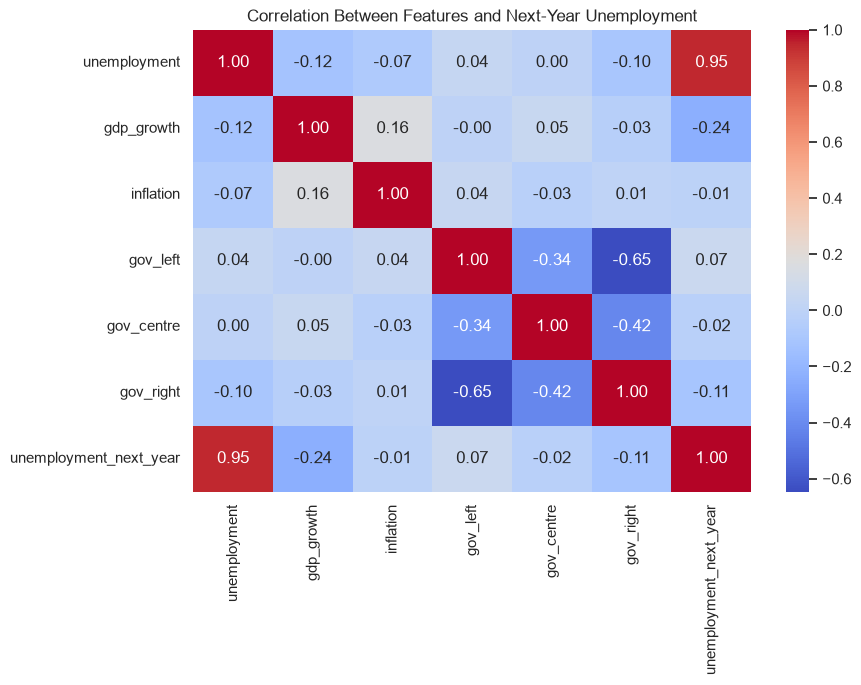

In [ ]:
features = [
    "unemployment",
    "gdp_growth",
    "inflation",
    "gov_left",
    "gov_centre",
    "gov_right"
]

# Calculate correlation matrix
corr = panel[
    features + ["unemployment_next_year"]
].corr()


plt.figure(figsize=(9, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Features and Next-Year Unemployment")
plt.show()

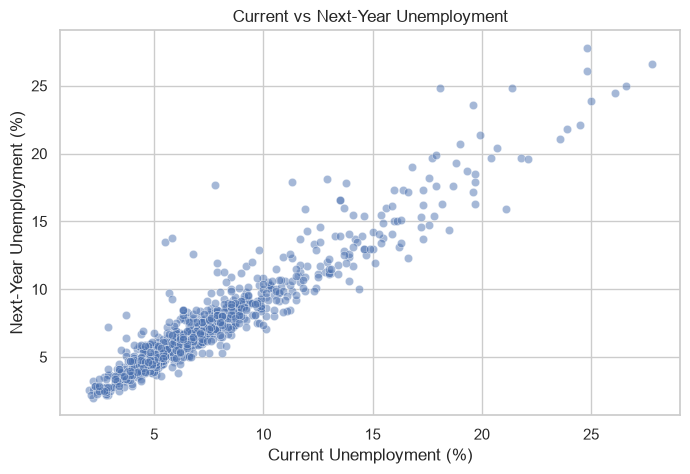

In [11]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=panel,
    x="unemployment",
    y="unemployment_next_year",
    alpha=0.5
)

plt.title("Current vs Next-Year Unemployment")
plt.xlabel("Current Unemployment (%)")
plt.ylabel("Next-Year Unemployment (%)")

plt.show()

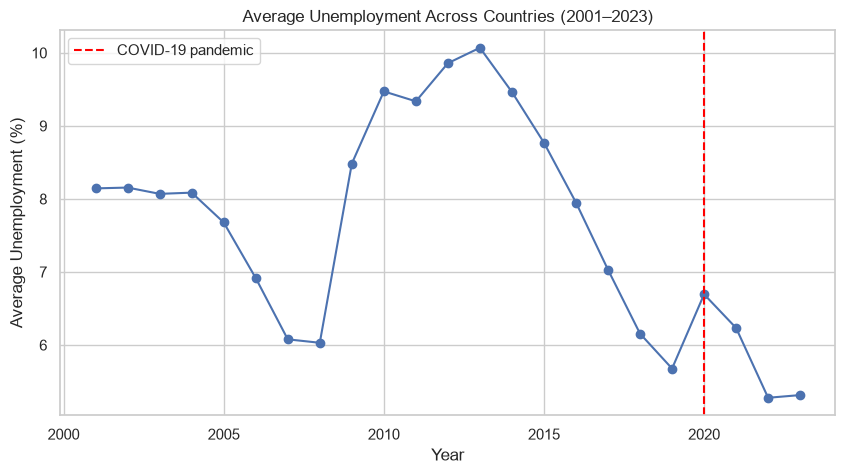

In [12]:
# Calculate average unemployment across countries by year
yearly_unemployment = (
    panel.groupby("target_year")["unemployment_next_year"]
    .mean()
)

plt.figure(figsize=(10, 5))

plt.plot(
    yearly_unemployment.index,
    yearly_unemployment.values,
    marker="o"
)

# Mark beginning of pandemic
plt.axvline(
    x=2020,
    color="red",
    linestyle="--",
    label="COVID-19 pandemic"
)

plt.title("Average Unemployment Across Countries (2001–2023)")
plt.xlabel("Year")
plt.ylabel("Average Unemployment (%)")
plt.legend()

plt.show()

In [13]:
corr["unemployment_next_year"].sort_values(ascending=False)

unemployment_next_year    1.000000
unemployment              0.948058
gov_left                  0.067343
inflation                -0.005546
gov_centre               -0.024811
gov_right                -0.109881
gdp_growth               -0.236928
Name: unemployment_next_year, dtype: float64

### Correlation Analysis

The correlation analysis shows that current unemployment has the strongest relationship with next-year unemployment (r = 0.948). This suggests that unemployment is highly persistent over time.

GDP growth has a weak negative correlation (r = −0.237), suggesting that stronger economic growth is associated with lower unemployment in the following year.

Inflation shows almost no linear correlation with next-year unemployment (r = −0.006).

Government political composition variables show weak correlations, ranging from approximately −0.110 to +0.067.

These findings suggest that current unemployment and GDP growth may be useful predictors. However, correlation alone does not establish causation or determine a feature's usefulness in a multivariable prediction model.

---
## 8. Split once

A fixed `random_state`, stratified for classification. From here on, everything happens on the training set; the test set waits until notebook 03.

In [14]:
features = [
    "unemployment",
    "gdp_growth",
    "inflation",
    "gov_left",
    "gov_centre",
    "gov_right"
]

# Training data: before COVID
train = panel[panel["year"] <= 2018].copy()

# Test data: pandemic and following years
test = panel[panel["year"] >= 2019].copy()

# Predictors and target
X_train = train[features]
y_train = train["unemployment_next_year"]

X_test = test[features]
y_test = test["unemployment_next_year"]

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

Training shape: (684, 6)
Test shape: (142, 6)


---
## 9. Baseline

A `DummyClassifier` or `DummyRegressor`, scored with the cross-validation you will use for every model. Write the number down: it is what next week's models have to beat.

In [15]:
import numpy as np

cv_splits = []

for end_year in [2008, 2012, 2016]:

    train_idx = np.where(
        train["target_year"] <= end_year
    )[0]

    val_idx = np.where(
        (train["year"] >= end_year + 1) &
        (train["year"] <= end_year + 2)
    )[0]

    cv_splits.append((train_idx, val_idx))

In [16]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

baseline = make_pipeline(
    SimpleImputer(strategy="median"),
    DummyRegressor(strategy="mean")
)

scores = -cross_val_score(
    baseline,
    X_train,
    y_train,
    cv=cv_splits,
    scoring="neg_mean_absolute_error"
)

print("MAE for each fold:", scores)
print("Average DummyRegressor MAE:", scores.mean())

MAE for each fold: [3.25005787 3.39031636 3.45032793]
Average DummyRegressor MAE: 3.3635673868312757


In [17]:
persistence_scores = []

for train_idx, val_idx in cv_splits:

    actual = y_train.iloc[val_idx]
    predicted = X_train.iloc[val_idx]["unemployment"]

    mae = (actual - predicted).abs().mean()

    persistence_scores.append(mae)

print("MAE for each fold:", persistence_scores)
print("Average Persistence MAE:", np.mean(persistence_scores))

MAE for each fold: [np.float64(1.0458333333333334), np.float64(0.7805555555555556), np.float64(0.7180555555555557)]
Average Persistence MAE: 0.8481481481481481


In [18]:
print(f"DummyRegressor MAE: {scores.mean():.3f}")
print(f"Persistence MAE:    {np.mean(persistence_scores):.3f}")

DummyRegressor MAE: 3.364
Persistence MAE:    0.848


### Baseline Evaluation

I evaluated two baseline approaches using chronological cross-validation and Mean Absolute Error (MAE).

The DummyRegressor, which predicts the average unemployment rate in the training data, achieved an MAE of **3.364 percentage points**.

The persistence baseline, which assumes next year's unemployment rate will equal the current year's rate, achieved an MAE of **0.848 percentage points**.

The persistence baseline reduced prediction error by approximately 75% compared with the DummyRegressor.

These findings confirm that current unemployment is a strong predictor of unemployment in the following year.

The goal for subsequent machine learning models is to outperform the persistence baseline while incorporating economic and political variables.

---
## 10. Into notebook 02

The columns you keep and how each type will be prepared, the features you want to try, and the models you will compare.

### Next Steps

In Notebook 02, I will develop and compare three regression models:

1. **Linear Regression** — to identify linear relationships between economic indicators, government political composition, and future unemployment.
2. **Ridge Regression** — to reduce overfitting by regularizing regression coefficients.
3. **Random Forest Regressor** — to investigate potential nonlinear relationships.

I will use the same chronological cross-validation strategy and MAE metric to compare all models.

Missing predictor values will be handled using median imputation within the modeling pipeline.

The persistence baseline MAE of 0.848 percentage points will serve as the main benchmark.

The final selected model will be evaluated on the previously unseen 2020–2023 unemployment outcomes to investigate its performance during and after the COVID-19 pandemic.

---
## Image option

If you chose the flower photos, sections 3 to 7 become: a grid of example photos per class, the number of photos per class, the range of image sizes, and a few photos that are hard or look mislabelled. Section 8 is a fixed split into training, validation and test sets with `image_dataset_from_directory` and a seed. Section 9 is the majority-class accuracy.